# Recolor the object


## imports

In [1]:
%matplotlib widget

from utils import *
from ipywidgets import interact

## read image + mask

frames : 100


(<Figure size 1000x400 with 2 Axes>,
 array([[<Axes: title={'center': 'frame 50'}>,
         <Axes: title={'center': 'mask 50'}>]], dtype=object))

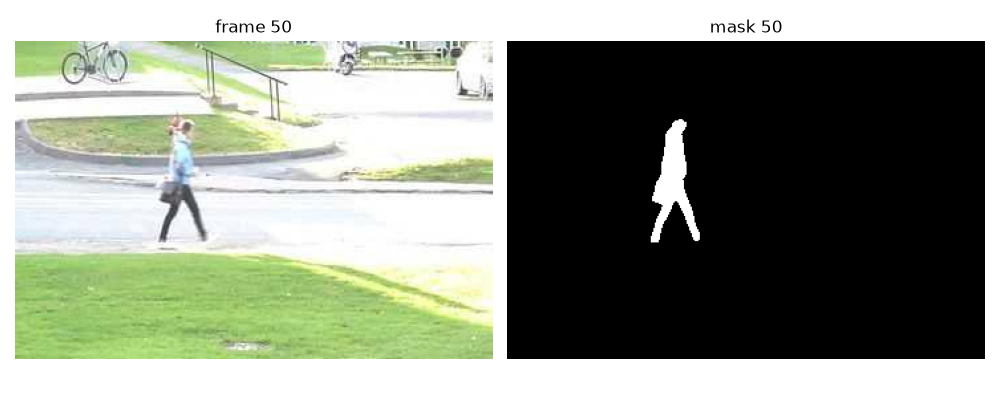

In [3]:
nb_frames = len(os.listdir(FRAMES_dir))
print("frames :", nb_frames)

frame = load_frame(50)
mask = load_mask(50)
imshow([frame, mask * 255], ["frame 50", "mask 50"])

## HSV

rgb2hsv

(<Figure size 1200x300 with 3 Axes>,
 array([[<Axes: title={'center': 'hue'}>,
         <Axes: title={'center': 'saturation'}>,
         <Axes: title={'center': 'value'}>]], dtype=object))

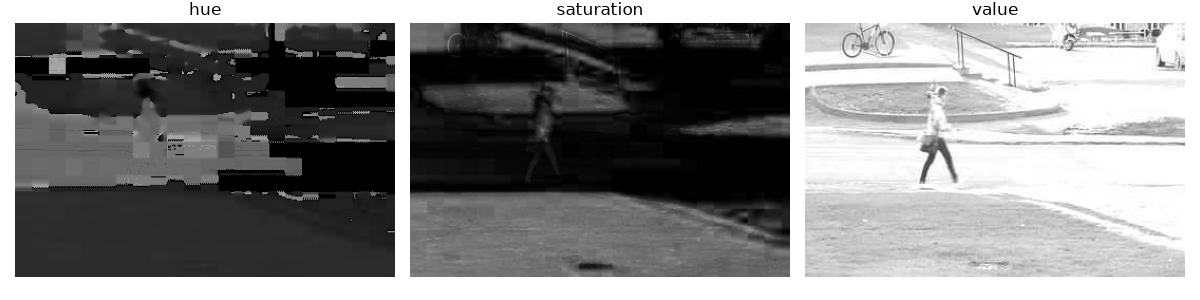

In [4]:
#convert RGB -> HSV
hsv = cv2.cvtColor(frame, cv2.COLOR_RGB2HSV)

#look at the 3 channels
imshow([hsv[:, :, 0], hsv[:, :, 1], hsv[:, :, 2]], ["hue", "saturation", "value"], figsize=(12, 3))

## RECOLOR

In [5]:
def recolor(frame, mask, hue=None, hue_shift=0, satur_add=0, val_mult=1.0):
    #if hue = None, keep original color
    hsv = cv2.cvtColor(frame, cv2.COLOR_RGB2HSV).astype(np.float32)
    h = hsv[:, :, 0]
    s = hsv[:, :, 1]
    v = hsv[:, :, 2]

    #change only the object pixels : 
    if hue is not None : 
        h[mask] = hue
    h[mask] = (h[mask]+ hue_shift) % 180
    s[mask] = np.clip(s[mask] + satur_add, 0, 255)
    v[mask] = np.clip(v[mask]*val_mult, 0, 255)

    hsv = hsv.astype(np.uint8)
    return cv2.cvtColor(hsv, cv2.COLOR_HSV2RGB)


## Test

(<Figure size 1000x300 with 5 Axes>,
 array([[<Axes: title={'center': 'original'}>,
         <Axes: title={'center': 'green'}>,
         <Axes: title={'center': 'blue'}>,
         <Axes: title={'center': 'grey'}>,
         <Axes: title={'center': 'darker'}>]], dtype=object))

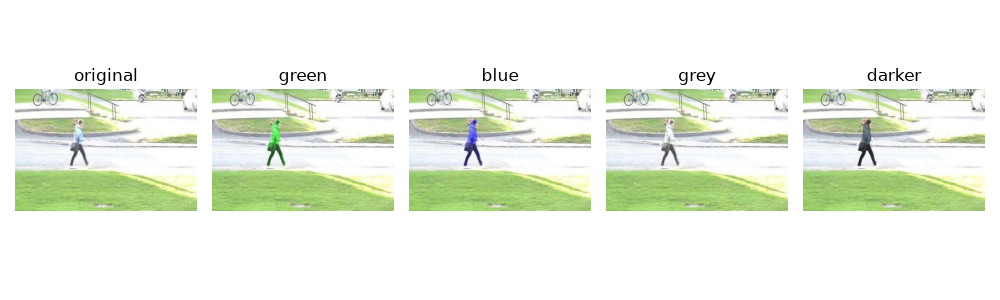

In [10]:
imshow([frame, recolor(frame, mask, hue=60, satur_add=100), recolor(frame, mask, hue=120, satur_add=100), recolor(frame, mask, satur_add=-255), recolor(frame, mask, val_mult=0.5)], ["original", "green", "blue", "grey", "darker"], figsize=(10, 3),)

## Soft edges

A pixel is either recolored or not, so we see the difference at the edges
mix new color and old color 

## Cursors

interactive(children=(IntSlider(value=50, description='i', max=99), IntSlider(value=60, description='hue', max…

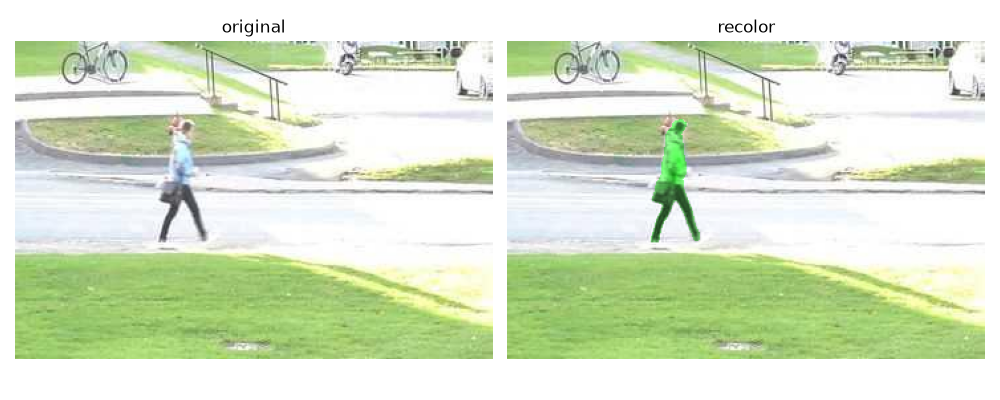

In [16]:
#create the figure only once (because of %widget)
frame = load_frame(50)
fig, axeslist = imshow([frame, frame], ["original", "recolor"], figsize=(10, 4))
left = axeslist[0, 0].images[0]
right = axeslist[0, 1].images[0]


@interact(i=(0, nb_frames - 1), hue=(0, 179), satur_add=(-255, 255), val_mult=(0.2, 2.0, 0.1))
def show(i=50, hue=60, satur_add=100, val_mult=1.0):
    frame = load_frame(i)
    mask = load_mask(i)
    result = recolor(frame, mask, hue=hue, satur_add=satur_add, val_mult=val_mult)

    #replace images inside the same figure
    left.set_data(frame)
    right.set_data(result)
    fig.canvas.draw_idle()

## all the video

video saved


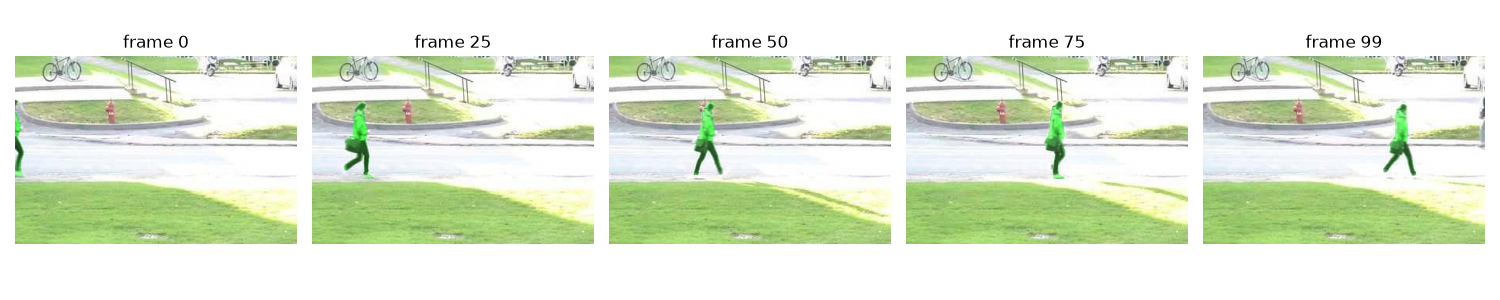

In [19]:
recolor_frames = []
for i in range(nb_frames):
    result = recolor(load_frame(i), load_mask(i), hue=60, satur_add=100, val_mult=1.0)
    recolor_frames.append(result)

#check 5 frames
check = [0, nb_frames // 4, nb_frames // 2, 3 * nb_frames // 4, nb_frames - 1]
imshow([recolor_frames[i] for i in check], [f"frame {i}" for i in check], figsize=(15, 3))

#save video
os.makedirs(OUTPUTS_dir, exist_ok=True)
save_video(recolor_frames, f"{OUTPUTS_dir}/recolor_hue{60}.mp4", fps=30)
print("video saved")